In [4]:
import chipwhisperer as cw
import numpy as np
import struct
import matplotlib.pyplot as plt
import time
scope = cw.scope()
target = cw.target(scope)
scope.default_setup()

USBErrorBusy: LIBUSB_ERROR_BUSY [-6]

In [5]:
'''
Programs the target
'''

import os

# =============================================================================
# 1. Target Setup & Firmware Compilation
# =============================================================================

# Define the hardware platform (CW308 baseboard with an STM32F3 target MCU)
PLATFORM = 'CW308_STM32F3'
FW_PATH = "../firmware/measureARM/"
!make -C "{FW_PATH}" PLATFORM={PLATFORM} CRYPTO_TARGET=NONE
hex_path = os.path.join(FW_PATH, f"measure-{PLATFORM}.hex")
cw.program_target(scope, cw.programmers.STM32FProgrammer, hex_path)


make: Entering directory '/home/eyobed/Documents/School/BUT/Semester 2/YP2/src/32-bit/firmware/measureARM'
SS_VER set to SS_VER_1_1
SS_VER set to SS_VER_1_1
.
Welcome to another exciting ChipWhisperer target build!!
arm-none-eabi-gcc (15:14.2.rel1-1) 14.2.1 20241119
Copyright (C) 2024 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

mkdir -p objdir-CW308_STM32F3 
.
Compiling:
-en     measure.c ...
-e Done!
.
Compiling:
-en     .././simpleserial/simpleserial.c ...
-e Done!
.
Compiling:
-en     .././hal/hal.c ...
-e Done!
.
Compiling:
-en     .././hal//stm32f3/stm32f3_hal.c ...
-e Done!
.
Compiling:
-en     .././hal//stm32f3/stm32f3_hal_lowlevel.c ...
-e Done!
.
Compiling:
-en     .././hal//stm32f3/stm32f3_sysmem.c ...
-e Done!
.
Assembling: .././hal//stm32f3/stm32f3_startup.S
arm-none-eabi-gcc -c -mcpu=cortex-m4 -I. -x assembler-with-cpp -mthumb -mfloat-a


--- Step 1: Measuring loop execution time up to 2000 iterations ---


Measuring:   0%|          | 0/200 [00:00<?, ?it/s]


--- Loop Timing Results ---
Time Per Iteration (Slope): 1.0833 μs/iter
Setup Overhead (Intercept): 2.3021 μs
R-squared (Linearity):      1.000000


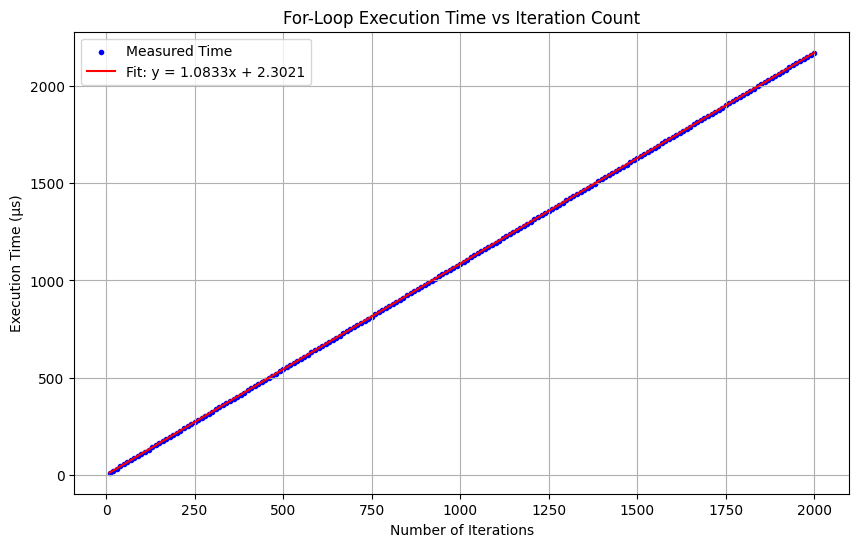


--- Step 2: Profiling PRNG Jitter over 2000 executions ---


PRNG Jitter:   0%|          | 0/2000 [00:00<?, ?it/s]

Mean execution time: 648.02 μs
Standard Deviation:  0.56 μs
Spread (Max - Min):  3.25 μs


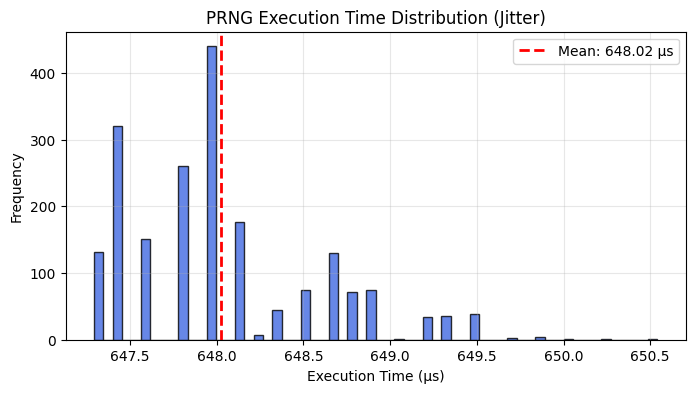

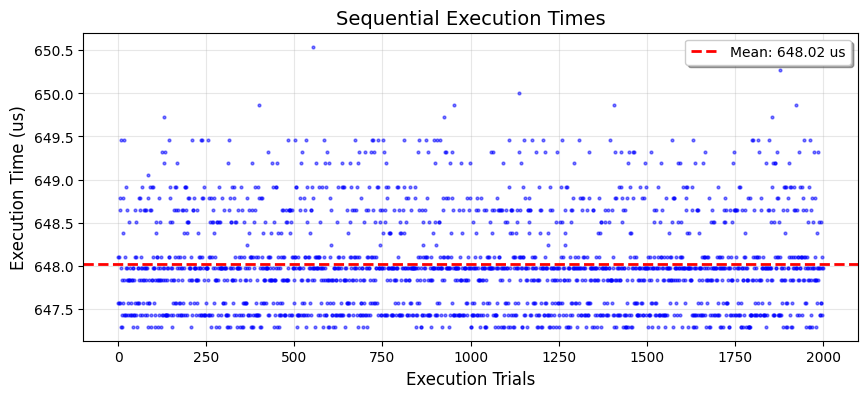

In [7]:
"""
ChipWhisperer Loop Timing measurer

This script interacts with an embedded ARM microcontroller (STM32F3) to mathematically 
characterize the execution time of a basic `for-loop`. By varying the number of iterations
and measuring the exact time taken using an oscilloscope's hardware trigger, we can use 
linear regression to isolate two important metrics:
1. Time per Iteration (Slope): The time taken to execute the loop body once.
2. Setup Overhead (Intercept): The constant time taken for function calls, returns, 
   and initial variable setup, regardless of loop length.

Prerequisites: A Jupyter/IPython environment with an initialized `scope` and `target` 
object from the ChipWhisperer API.
"""

import struct
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from tqdm.notebook import tqdm

# =============================================================================
# Phase 1: Loop Profiling (Command 'l')
# =============================================================================

def measure_loop_timing(max_iters=2000, step=10):
    """
    Empirically measures and statistically models the execution time of a loop.
    
    Args:
        cmd_char (str): The SimpleSerial command byte the firmware listens for.
        max_iters (int): The maximum number of loop iterations to test.
        step (int): The increment between iteration counts (e.g., 10, 20, 30...).
        
    Returns:
        tuple: (slope in microseconds/iteration, intercept in microseconds)
    """
    
    # Generate an array of iteration counts to test (e.g., [10, 20, 30, ... max_iters])
    iteration_counts = np.arange(10, max_iters + 1, step)
    
    # List to hold the empirically measured time for each iteration count
    execution_times_us = []
    
    # Retrieve the oscilloscope's Analog-to-Digital Converter (ADC) sampling frequency.
    # We need this to convert raw hardware clock ticks into standard time (microseconds).
    adc_freq = scope.clock.adc_freq 

    print(f"\n--- Step 1: Measuring loop execution time up to {max_iters} iterations ---")
    
    # Iterate through the generated counts with a UI progress bar
    for iters in tqdm(iteration_counts, desc="Measuring"):
        
        # --- Payload Construction ---
        # struct.pack('<H', int(iters)) formats the integer into bytes.
        # '<' ensures Little-Endian byte order (standard for ARM Cortex-M).
        # 'H' specifies an unsigned 16-bit integer (uint16_t in C), meaning 
        # iters cannot exceed 65,535.
        pt = bytearray(struct.pack('<H', int(iters)))
        
        # --- Execution & Measurement ---
        # Arm the oscilloscope. It will now wait for the MCU's trigger pin to go HIGH.
        scope.arm()
        
        # Send the command character and the 2-byte payload to the MCU via UART.
        target.simpleserial_write('l', pt)
        
        # Block and wait until the MCU drops the trigger pin LOW, signaling completion.
        ret = scope.capture()
        if ret:
            print("Timeout error! The trigger never fired or finished.")
            break
            
        # --- Data Extraction ---
        # Extract the exact number of sampling clock cycles the trigger was held HIGH
        cycles = scope.adc.trig_count
        
        # Convert the discrete cycle count to physical time (microseconds)
        time_us = (cycles / adc_freq) * 1e6 
        execution_times_us.append(time_us)
        
        # --- State Reset ---
        # Read the 1-byte acknowledgment from the target. This ensures the firmware's 
        # UART buffer is flushed and ready for the next iteration without desyncing.
        target.simpleserial_read('r', 1)


    # =============================================================================
    # 3. Statistical Analysis (Linear Regression)
    # =============================================================================
    
    # We apply the formula: y = mx + b
    # y = Total Execution Time
    # x = Number of Iterations
    # m = Slope (Time consumed per single loop iteration)
    # b = Intercept (Base overhead: function call, context switch, variable init)
    slope, intercept, r_value, p_value, std_err = linregress(
        iteration_counts[:len(execution_times_us)], # X-axis data
        execution_times_us                          # Y-axis data
    )
    
    print("\n--- Loop Timing Results ---")
    print(f"Time Per Iteration (Slope): {slope:.4f} μs/iter")
    print(f"Setup Overhead (Intercept): {intercept:.4f} μs")
    # R-squared near 1.0 indicates a perfect linear relationship (highly predictable CPU)
    print(f"R-squared (Linearity):      {r_value**2:.6f}")
    
    
    # =============================================================================
    # 4. Visualization
    # =============================================================================
    
    plt.figure(figsize=(10, 6))
    
    # Scatter plot of the actual raw data points captured from the oscilloscope
    plt.scatter(iteration_counts[:len(execution_times_us)], execution_times_us, 
                marker='.', color='blue', label='Measured Time')
    
    # Generate and plot the idealized line of best fit based on the regression model
    best_fit_line = slope * iteration_counts + intercept
    plt.plot(iteration_counts, best_fit_line, color='red', 
             label=f'Fit: y = {slope:.4f}x + {intercept:.4f}')
    
    # Graph formatting
    plt.title("For-Loop Execution Time vs Iteration Count")
    plt.xlabel("Number of Iterations")
    plt.ylabel("Execution Time (μs)")
    plt.legend()
    plt.grid(True)
    plt.show()
    
    return slope, intercept

# =============================================================================
# Phase 2: PRNG Jitter Profiling (Command 'g')
# =============================================================================

def measure_prng_jitter(num_traces=2000):
    execution_times_us = []
    adc_freq = scope.clock.adc_freq 
    
    print(f"\n--- Step 2: Profiling PRNG Jitter over {num_traces} executions ---")

    # --- DUMMY TRACE TO WARM UP THE CACHE ---
    scope.arm()
    target.simpleserial_write('g', b'')
    scope.capture()
    target.simpleserial_read('r', 1) 
    # Notice we don't append the time_us of this trace
    # ----------------------------------------
    
    for _ in tqdm(range(num_traces), desc="PRNG Jitter"):
        scope.arm()
        
        # Send the 'g' command. Notice the payload is empty (b'') because 
        # the firmware expects 0 bytes for this specific command.
        target.simpleserial_write('g', b'')
        
        if scope.capture():
            print("Timeout error during PRNG profiling!")
            break
            
        time_us = (scope.adc.trig_count / adc_freq) * 1e6 
        execution_times_us.append(time_us)
        target.simpleserial_read('r', 1) # Clear Ack
        
    times_us = np.array(execution_times_us)
    
    # Statistics
    mean_val = np.mean(times_us)
    print(f"Mean execution time: {mean_val:.2f} \u03bcs")
    print(f"Standard Deviation:  {np.std(times_us):.2f} \u03bcs")
    print(f"Spread (Max - Min):  {(np.max(times_us) - np.min(times_us)):.2f} \u03bcs")
    
    # Plotting
    plt.figure(figsize=(8, 4))
    plt.hist(times_us, bins=60, color='royalblue', edgecolor='black', alpha=0.8)
    plt.axvline(mean_val, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_val:.2f} \u03bcs')
    plt.title('PRNG Execution Time Distribution (Jitter)')
    plt.xlabel('Execution Time (\u03bcs)')
    plt.ylabel('Frequency')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # Scatter Plot
    plt.figure(figsize=(10, 4))
    plt.plot(times_us, marker='.', linestyle='', markersize=4, color='blue', alpha=0.5)
    plt.axhline(mean_val, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_val:.2f} us')
    plt.title('Sequential Execution Times', fontsize=14)
    plt.xlabel('Execution Trials', fontsize=12)
    plt.ylabel('Execution Time (us)', fontsize=12)
    plt.legend(loc='upper right', frameon=True, shadow=True)
    plt.grid(True, alpha=0.3)
    plt.show()

# =============================================================================
# Execution
# =============================================================================

measure_loop_timing(max_iters=2000, step=10)
measure_prng_jitter(num_traces=2000)